# County Level Stochastic SI Modeling of White-Nose Syndrome

## Project Overview

This project explores potential disease spread through a network of U.S. counties using stochastic modeling and Monte Carlo simulation. 

Each county is represented as a node in an undirected graph, with edges representing the geographic connection between neighboring counties. 

A stochastic SI (Susceptible-Infected) model is used to simulate potential disease transmission through the network between connected counties.
Monte Carlo simulations are then used to estimate county-level infection probabilities over a 5-step simulated timeline.

The project combines graph theory, probability modeling, computational simulation and geographic data visualization using Python.

## Python Imports

In [1]:
#Data manipulation
import pandas as pd
import numpy as np

#Network modeling
import networkx as nx

#Geographic mapping and analysis
import geopandas as gpd

#Visualization tools
import matplotlib.pyplot as plt
import seaborn as sns

sns.set()

## County Adjacency Data from U.S. Census

In [2]:
#Read in csv to make network of US counties
adjacency = pd.read_csv('../data/raw/county_adjacency2026.txt', sep = '|', header = 0, dtype = str)

adjacency.head()

,County Name,County GEOID,Neighbor Name,Neighbor GEOID,Length
0,"Autauga County, AL",01001,"Chilton County, AL",01021,52284
1,"Autauga County, AL",01001,"Dallas County, AL",01047,51498
2,"Autauga County, AL",01001,"Elmore County, AL",01051,32990
3,"Autauga County, AL",01001,"Lowndes County, AL",01085,59159
4,"Autauga County, AL",01001,"Montgomery County, AL",01101,14548


In [3]:
#Use a county to test geoid recall
jeffco_geoid = adjacency.loc[adjacency['County Name'] == 'Jefferson County, CO', 'County GEOID'].iloc[0]

print(jeffco_geoid)

08059


## County Network Construction

In [4]:
#drop any rows without neighbor identities
adjacency_edges = adjacency.dropna(
    subset=['County GEOID', 'Neighbor GEOID']
).copy()

#Create a network using the cleaned dataframe, and make that network a graph
G = nx.from_pandas_edgelist(adjacency_edges, source = 'County GEOID', target = 'Neighbor GEOID', edge_attr = 'Length', create_using = nx.Graph())

In [5]:
print('Number of counties:', G.number_of_nodes())
print('Number of connections:', G.number_of_edges())

print(
    'Connected components:',
    nx.number_connected_components(G)
)

print(f'Isolated Counties: {len(list(nx.isolates(G)))}')

Number of counties: 3225
Number of connections: 9479
Connected components: 7
Isolated Counties: 0


## Network Exploration

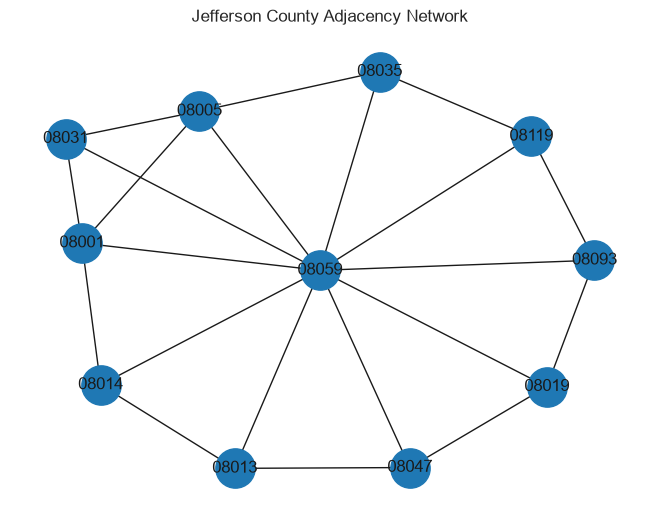

In [6]:
#Test of netowkr on small scale

#Find neighbors of the specified county from above using geoid recalled
neighbors = list(G.neighbors(jeffco_geoid))

#Create a region of the graph containing target countiues and neighbors
region = [jeffco_geoid] + neighbors

#Make the region into a subgraph
jeffco_subgraph = G.subgraph(region)

#Use a spring layout to create position data for the subgraph
pos = nx.spring_layout(jeffco_subgraph, seed=22)

#draw the subgraph using the spring layout positions
nx.draw(
    jeffco_subgraph,
    pos,
    with_labels=True,
    node_size=800
)

#show the graph and title
plt.title('Jefferson County Adjacency Network')
plt.show()

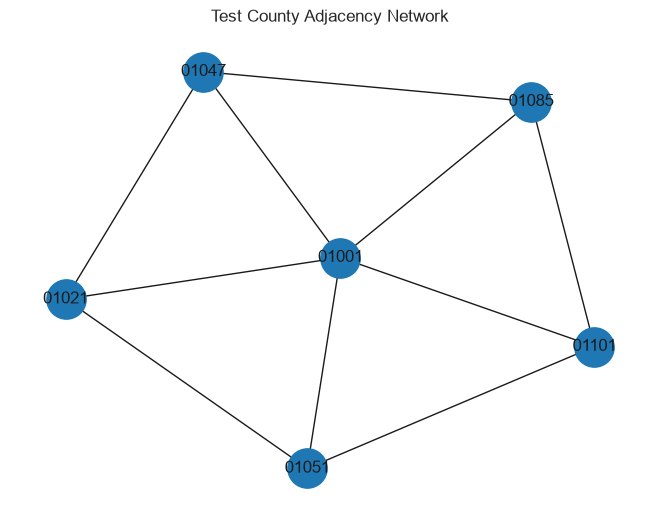

In [7]:
#Repeat above procedure to generate another test graph using new GEOID
test_geoid = '01001'

neighbors = list(G.neighbors(test_geoid))

region = [test_geoid] + neighbors

test_subgraph = G.subgraph(region)

pos = nx.spring_layout(test_subgraph, seed=22)

nx.draw(
    test_subgraph,
    pos,
    with_labels=True,
    node_size=800
)

plt.title('Test County Adjacency Network')
plt.show()

## Stochastic Disease Spread Model

This model assumes that all infected neighbors are equally likely to spread infection to neighbors. This model is shown below:

$$P_{i}(t) = 1 - (1 - \beta)^{k_{i}(t)}$$

Where $P_{i}$ is the calculated probability of being infected, $\beta$ represents the ability of a disease to spread to neighboring counties, 
and $k_{i}(t)$ is the amount of neighboring counties infected

In [8]:
#Create a funciton to be used stochastically to simulate disease spread through a network
def spread_simulation(G, initial_infected, spread_chance, timeframe, seed):
    '''Stochastic model to simulate disease spread through a network, based on a single spread chance parameter. Requires network, list of initially infected nodes,
    the chance of the disease spreading, the timeframe for the simulation to run on, and a seed to generate rng'''

    #Create rng set to be used
    rng = np.random.default_rng(seed=seed)

    #Use initial list of infected nodes to create a set
    infected = set(initial_infected)

    #Create a copy of initial infected to be stored in history
    timeline = [infected.copy()]

    #Iterate through desired time of simulations
    for year in range(timeframe):

        #Create a blank set to store newly infected nodes in
        new_infections = set()

        #Iterate through all nodes
        for county in G.nodes():

            #Skip county if it is already infected
            if county in infected:
                continue

            #County how many connecting nodes are infected
            k= sum(neighbor in infected for neighbor in G.neighbors(county))

            #If no infected neighbors, assume no infection spread risk
            if k == 0:
                continue

            #Calculate infection chance using spread chance and number of neighbors
            infection_chance = 1 - (1 - spread_chance) ** k

            #Check against rng for stochastic simulation
            if rng.random() < infection_chance:

                #If rng check succedes make the county infected
                new_infections.add(county)

        #Update infected list with new infections
        infected.update(new_infections)

        #Add infected list to timeline to track history
        timeline.append(infected.copy())

    return timeline

## Single Simulation

In [9]:
#Provide arbitrary intial infected county, desired timeframe in years, and arbitrary spread chance
initial_infected = [jeffco_geoid]
timeframe = 5
spread_chance = 0.1

#Call above created function
timeline = spread_simulation(G, initial_infected = initial_infected, spread_chance = spread_chance, timeframe = timeframe, seed = 22) 


In [10]:
#Print timeline to check
for year, infected in enumerate(timeline):
    print(f'year {year}, infected counties: {len(infected)}')

year 0, infected counties: 1
year 1, infected counties: 3
year 2, infected counties: 4
year 3, infected counties: 6
year 4, infected counties: 8
year 5, infected counties: 8


## Monte Carlo Simulation

### Initial Conditions
For the exploratory simulation, two counties are selected as initialy infected counties to demonstrate how the stochastic simulation would
propogate through the network of counties. 

The current transmission parameter is set at $0.1$, which is a purely illustrative value.

These counties sre hypothetical starting conditions and are not designated as historically accurate WNS locations. Future verions will
incorporate historical WNS surveillance records to estrablish initial infecion locations, and create robust parameters to show likelihood of transmission betwen counties

In [11]:
#Set parameters of 1000 simulations, 5 year timeframe, 2 arbitrary infected counties, and arbitrarry spread chance
n_sims = 1000
timeframe = 5
initial_infected = [test_geoid, jeffco_geoid]
spread_chance = 0.1

#Create a list of all nodes in network
nodes = list(G.nodes)

#Create an array of zeros big enough to store all years and all nodes
infection_counts = np.zeros((timeframe+1, len(nodes)))

#Create index to iterate through list with
node_index = {county: i for i, county in enumerate(nodes)}

#Create a blank array of zeros to store total infection numbers in for all years
total_infected = np.zeros((n_sims, timeframe + 1))

#For every desired simulation use created function to model spread
for sim in range(n_sims):
    timeline = spread_simulation(G, initial_infected = initial_infected, spread_chance = spread_chance, timeframe = timeframe, seed = sim)

    for year, infected in enumerate(timeline):
        
        #Update total infected array with how many counties are infected in this simulation
        total_infected[sim, year] = len(infected)

        for county in infected:

            #If the county is in the infected list update the array at this counties postition to show in this simulation it was infected
            infection_counts[year, node_index[county]] += 1

In [12]:
print(f'Number of simulations: {n_sims}')

print(f'Average infected counties by year: ' 
f'{total_infected.mean(axis = 0)}')

Number of simulations: 1000
Average infected counties by year: [ 2.     3.476  5.415  7.924 11.033 14.789]


In [13]:
#Generate Monte Carlo results using simulation to find counties frequently infected
infected_probability = infection_counts/n_sims

results = pd.DataFrame({
    'GEOID': nodes, 'Year 1': infected_probability[1], 'Year 2': infected_probability[2], 'Year 3': infected_probability[3],
    'Year 4': infected_probability[4], 'Year 5': infected_probability[5]
})

## Probability Analysis

In [14]:
#Identify counties with the highest simulated infection probability
results.sort_values(by = 'Year 5', ascending = False).head(25)

,GEOID,Year 1,Year 2,Year 3,Year 4,Year 5
0,01001,1.000,1.000,1.000,1.000,1.000
351,08059,1.000,1.000,1.000,1.000,1.000
348,08005,0.103,0.204,0.332,0.454,0.564
347,08001,0.094,0.213,0.336,0.449,0.560
379,08013,0.087,0.204,0.312,0.421,0.536
361,08035,0.095,0.184,0.290,0.412,0.534
1,01021,0.102,0.208,0.318,0.430,0.534
4,01085,0.096,0.226,0.331,0.444,0.532
387,08093,0.103,0.211,0.317,0.422,0.530
407,08119,0.091,0.196,0.319,0.430,0.522


[ 2.     3.476  5.415  7.924 11.033 14.789]


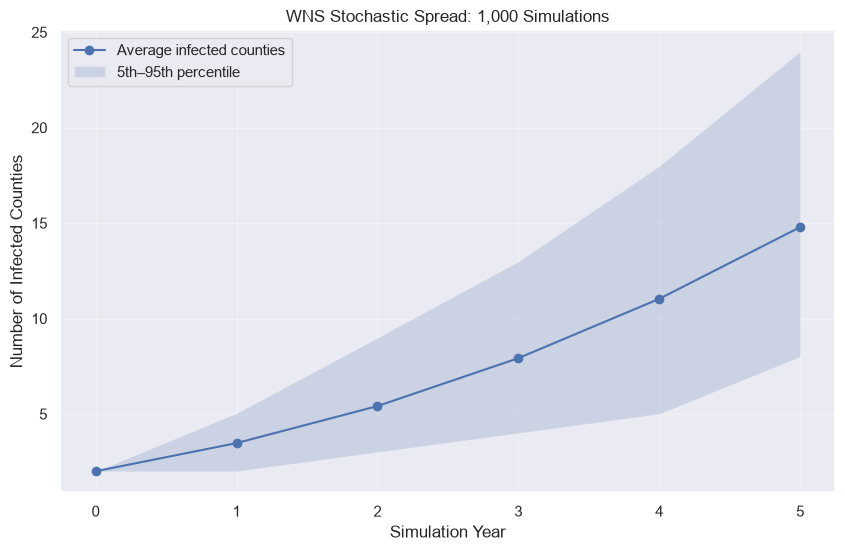

In [15]:
#Calculate the mean of how many counties were infected for every sim in each year
mean_infected = total_infected.mean(axis=0)

print(mean_infected)

#Create central 90% simulation outcome interval
lower = np.percentile(total_infected, 5, axis=0)
upper = np.percentile(total_infected, 95, axis=0)

#Generate plot
plt.figure(figsize=(10, 6))

plt.plot(
    range(timeframe + 1),
    mean_infected,
    marker='o',
    label='Average infected counties'
)

#Fill between confidence interval
plt.fill_between(
    range(timeframe + 1),
    lower,
    upper,
    alpha=0.2,
    label='5th–95th percentile'
)

#Labels
plt.xlabel('Simulation Year')
plt.ylabel('Number of Infected Counties')
plt.title('WNS Stochastic Spread: 1,000 Simulations')
plt.legend()
plt.grid(alpha=0.3)

## Geographic Visualization

In [16]:
#Read in url on county data from the year data collection ended
county_url = ('https://www2.census.gov/geo/tiger/TIGER2026/COUNTY/tl_2026_us_county.zip')

#Use geopandas to real url to be used in mapping
counties = gpd.read_file(county_url)

display(counties.head())

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,NaN,37340,NaN,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.613, -80.98674 28.61301..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,NaN,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10364 38.5..."
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,294,35220,NaN,A,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787..."
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,NaN,19700,NaN,A,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2..."
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,428,20100,NaN,A,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241..."


## Results and Discussion

In [17]:
#Ensure all GEOID values in Monte Carlo results are 5 digit strings to match TIGER data
results['GEOID'] = (
    results['GEOID']
    .astype(str)
    .str.strip()
    .str.replace(r'\.0$', '', regex=True)
    .str.zfill(5)
)

#Make sure TIGER GEOIDS match the same format as results GEOIDS
counties['GEOID'] = counties['GEOID'].astype(str).str.zfill(5)

#Turn result probabilities to numbers from strings
results['Year 5'] = pd.to_numeric(results['Year 5'], errors='coerce')

results.to_csv('../outputs/tables/County_Infection_Probabilities.csv', index = False)

In [18]:
#Merge the 2 data frames of Monte Carlo results and TIGER data, stacking the matching GEOID columns, keeping all TIGER data
county_map = counties.merge(results[['GEOID', 'Year 5']], on='GEOID', how='left')

In [19]:
#Show new merged data frame
display(
    county_map[
        ['GEOID', 'NAME', 'Year 5']
    ].head(20)
)

,GEOID,NAME,Year 5
0,12009,Brevard,0.0
1,06055,Napa,0.0
2,18065,Henry,0.0
3,35029,Luna,0.0
4,10001,Kent,0.0
5,48481,Wharton,0.0
6,30049,Lewis and Clark,0.0
7,30043,Jefferson,0.0
8,30007,Broadwater,0.0
9,42071,Lancaster,0.0


In [20]:
#List of state FIPS in contiguous 48 and Washington DC to be used in mapping
state_fips = [
    '01', '04', '05', '06', '08', '09', '10', '11', 
    '12', '13', '16', '17', '18', '19', '20', '21', 
    '22', '23', '24', '25', '26', '27', '28', '29', 
    '30', '31', '32', '33', '34', '35', '36', '37', 
    '38', '39', '40', '41', '42', '44', '45', '46', 
    '47', '48', '49', '50', '51', '53', '54', '55', 
    '56'
]

#Make a map only using lower 48 and DC
us_counties = county_map[
    county_map['STATEFP'].isin(state_fips)
].copy()

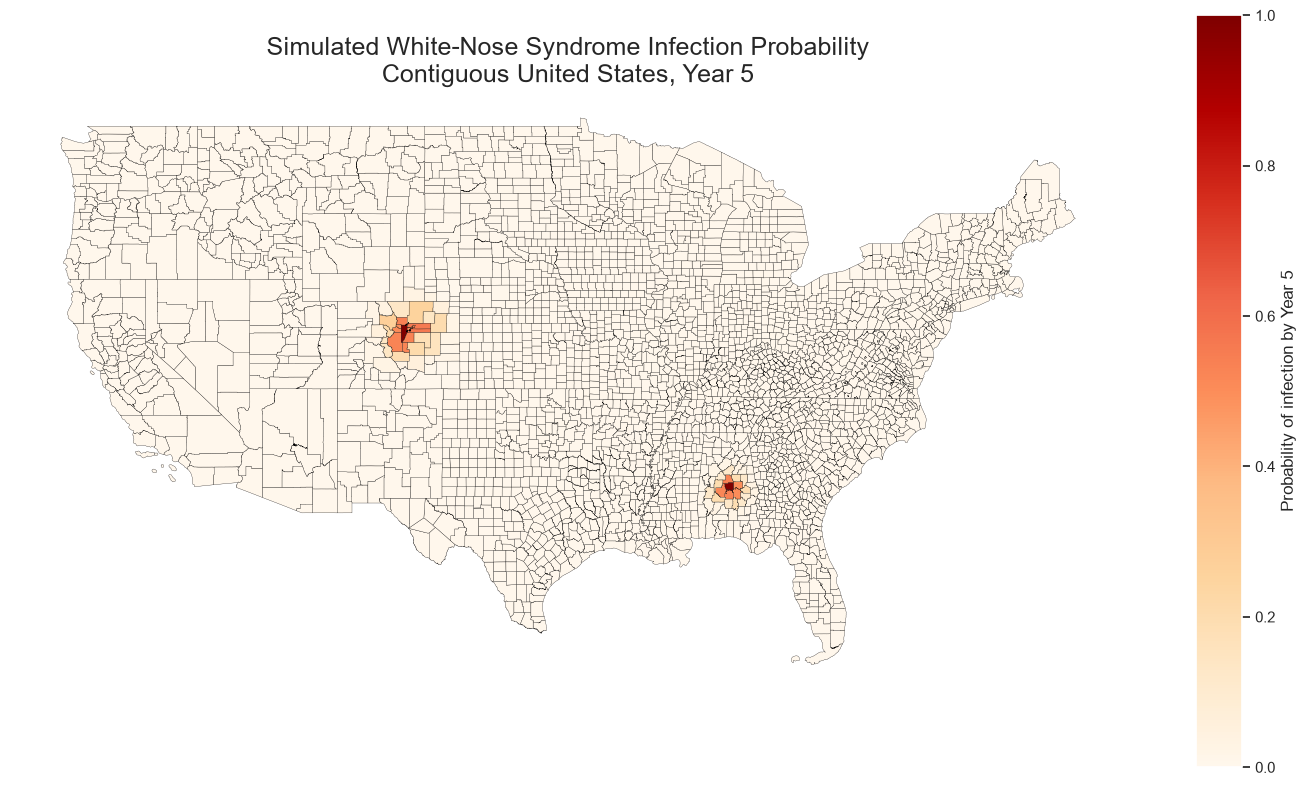

In [21]:
fig, ax = plt.subplots(figsize=(18, 12))

us_counties.plot(
    column='Year 5',
    cmap='OrRd',
    linewidth=0.2,
    edgecolor='black',
    legend=True,
    vmin=0,
    vmax=1,
    legend_kwds={
        'label': 'Probability of infection by Year 5',
    },
    ax=ax
)

ax.set_title(
    'Simulated White-Nose Syndrome Infection Probability'
    '\nContiguous United States, Year 5',
    fontsize=18,
)

ax.set_axis_off()

# Save map
plt.savefig('../outputs/figures/WNS_Year5_Probability_Map.png')

plt.show()

## Current Limitations

The current model exists as an exploratory stochastic network simulation with several limitations

1. Initial infection locations are hypothetical demonstration conditions rather than verified
    historical detections.
   
2. The transmission probability is assumed to be constant through all county connections.

3. Disease spread is limited to geographically adjacent counties.

4. Long-distance bat movement and other transmission pathways are not representd.

5. Environmental characteristics including cave density, bat habitat, winter climate, and others are not included.

6. The model does not distinguish between actual infection and recorded disease detection

7. Infected counties remain infected through the entire simulation

Future work will aim ot incorporate historical WNS surveillance, ecological variables, and model calibration against historical observations.